<a href="https://colab.research.google.com/github/SalmaAnindhia/PemMes_25_Salma/blob/main/JS07/Tugas_JS07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [2]:
df = pd.read_csv('CC_Customer_Dataset.csv')

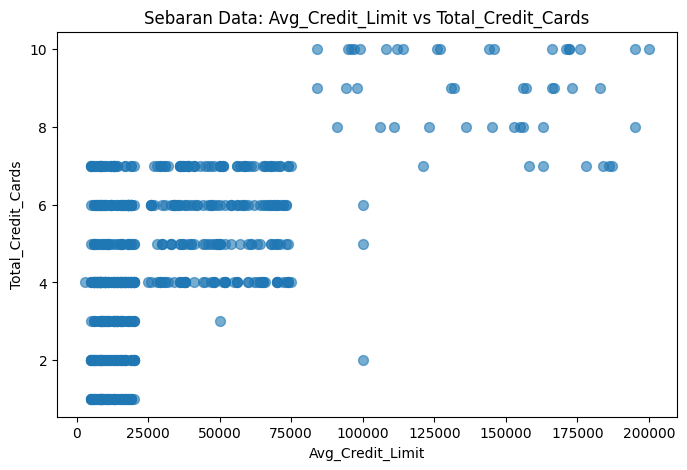

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'], s=50, alpha=0.6)
plt.xlabel('Avg_Credit_Limit'); plt.ylabel('Total_Credit_Cards')
plt.title('Sebaran Data: Avg_Credit_Limit vs Total_Credit_Cards')
plt.show()

sebaran data tidak dapat dikatakan linier, karna kelompok credit limit rendah menyebar sangat lebar pada semua jumlah kartu, sehingga batas antar kelompok saling tumpang-tindih dan tidak bisa dipisahkan dengan satu garis lurus

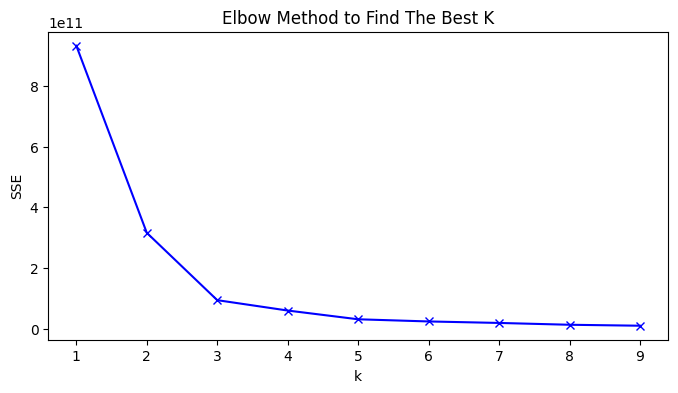

In [4]:
X = df[['Avg_Credit_Limit', 'Total_Credit_Cards']]

sse = []
K = range(1, 10)
for k in K:
    km = KMeans(n_clusters=k, random_state=0)
    km.fit(X)
    sse.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K, sse, "bx-")
plt.xlabel("k"); plt.ylabel("SSE")
plt.title("Elbow Method to Find The Best K")
plt.show()

Elbow ada di k=3 karena SSE turun tajam dari k=2 ke k=3 ±222 miliar, lalu melandai setelahnya ±34 miliar. Jadi jumlah cluster terbaik adalah 3, sesuai segmentasi nasabah yang jadi acuan.

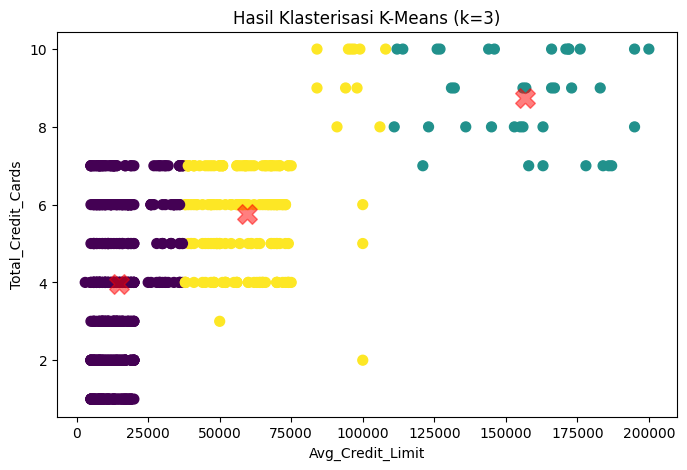

Nilai SSE (k=3): 93975905627.01657
[448  37 175]


In [5]:
cl_kmeans = KMeans(n_clusters=3, random_state=0)
y_kmeans = cl_kmeans.fit_predict(X)

plt.figure(figsize=(8, 5))
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=y_kmeans, s=50, cmap='viridis')

centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5, marker='X')
plt.xlabel('Avg_Credit_Limit'); plt.ylabel('Total_Credit_Cards')
plt.title('Hasil Klasterisasi K-Means (k=3)')
plt.show()

print(f'Nilai SSE (k=3): {cl_kmeans.inertia_}')
print(np.bincount(y_kmeans))

In [6]:
X_all = df.drop(columns=['Sl_No', 'Customer Key'])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_all)

dbscan = DBSCAN(eps=0.5, min_samples=5)
labels_db = dbscan.fit_predict(X_scaled)

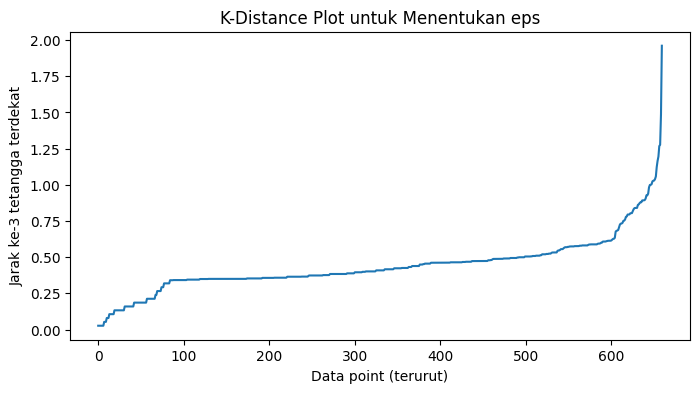

In [9]:
min_samples = 3
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)
distances = np.sort(distances[:, min_samples-1])

plt.figure(figsize=(8, 4))
plt.plot(distances)
plt.xlabel("Data point (terurut)")
plt.ylabel(f"Jarak ke-{min_samples} tetangga terdekat")
plt.title("K-Distance Plot untuk Menentukan eps")
plt.show()

Parameter min_samples=3 dipilih karena berada di posisi elbow, yaitu setelah titik ini tambahan informasi kerapatan tidak lagi signifikan. Nilainya cukup kecil untuk mengenali cluster yang rapat, tetapi cukup besar untuk menahan noise acak.

Nilai eps=0.6 diambil dari titik belok K-distance plot, tepat di ambang kerapatan alami data. Jika lebih kecil, cluster akan terpecah-pecah dan noise membengkak. Jika lebih besar, outlier premium ikut tersedot ke dalam cluster sehingga DBSCAN gagal mendeteksi noise.

Dengan parameter ini, DBSCAN menghasilkan 10 cluster (6 cluster utama beranggotakan 77-158 nasabah) dan 51 noise (7,7%). Hasilnya menangkap struktur kerapatan lokal yang lebih halus dibanding K-Means, yang hanya memaksa data menjadi 3 cluster.

In [8]:
mask = labels_db != -1
X_clean = X_scaled[mask]
labels_clean = labels_db[mask]

print(f"Jumlah cluster (tanpa noise): {len(set(labels_clean))}")
print(f"Jumlah noise: {(labels_db == -1).sum()} "
      f"({(labels_db == -1).mean()*100:.1f}%)")

print(f"Silhouette Score : {silhouette_score(X_clean, labels_clean)}")
print(f"Davies-Bouldin Index: {davies_bouldin_score(X_clean, labels_clean)}")

Jumlah cluster (tanpa noise): 24
Jumlah noise: 205 (31.1%)
Silhouette Score : 0.026998919881489288
Davies-Bouldin Index: 1.4334915083887771
